1. # Practical 2 report: from relationships to predictive models

**Student:** [Uliana Krektun]  
**Date:** [13.10.26]  
**Practical:** 2 - Regression and evaluation


In [76]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
import dcor
from sklearn.compose import ColumnTransformer
from sklearn.datasets import fetch_openml, load_diabetes
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
import sys, sklearn, pandas as pd, numpy as np

RANDOM_STATE = 99

## 2. Data-preparation readiness

Complete the checklist before describing modelling results. Tick an item only after checking the data or documenting a justified decision.

### Scientific purpose and provenance

- [X] Is the biological question and prediction task stated clearly? Can baseline physiological measurements predict quantitative diabetes disease progression?
- [X] Is the unit of observation clear? One diabetes patient
- [X] Do I know where the data came from, how they were generated, and under which access conditions they may be used?
- [X] Have I recorded the data version, processing history, and transformations already applied?

Ten baseline variables, age, sex, body mass index, average blood pressure, and six blood serum measurements were obtained for each of n = 442 diabetes patients, as well as the response of interest, a quantitative measure of disease progression one year after baseline. Each of these 10 feature variables have been mean centered and scaled by the standard deviation times the square root of n_samples (i.e. the sum of squares of each column totals 1).

### Table shape and identifiers

- [X] Is the table tidy: one observation per row, one variable per column, and one value per cell? Yes
- [X] If needed, have I transposed the original assay into the format expected by the analysis tool? Not needed
- [X] Are row names, column names, and identifiers clear, unique, and stable? Mostly yes, but the names of blood serum measurements columns are not clear without explanation.
- [X] Can every feature and observation be traced to its source?
- [X] Are the feature matrix and metadata aligned by an explicit identifier rather than row order? There is no separate metadata file.

In [7]:
diabetes = load_diabetes(as_frame=True)

diabetes_df = diabetes.frame.copy()
diabetes_df.head()

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


In [26]:
print(f"Python: {sys.version.split()[0]}")
print(f"scikit-learn: {sklearn.__version__}")
print(f"pandas: {pd.__version__}")
print(f"Dataset shape: {diabetes_df.shape}")

Python: 3.11.16
scikit-learn: 1.9.0
pandas: 3.0.5
Dataset shape: (442, 11)


### Types, values, and measurement meaning

- [X] Are numerical, categorical, ordinal, text, date, and identifier columns correctly classified?
- [X] Are units, scales, encodings, reference categories, and detection limits understood?
- [X] Have impossible values, inconsistent labels, unexpected categories, constant features, and extreme values been checked?
- [X] Are normalization, scaling, log transformation, and batch-correction steps documented?

In [9]:
diabetes_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 442 entries, 0 to 441
Data columns (total 11 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   age     442 non-null    float64
 1   sex     442 non-null    float64
 2   bmi     442 non-null    float64
 3   bp      442 non-null    float64
 4   s1      442 non-null    float64
 5   s2      442 non-null    float64
 6   s3      442 non-null    float64
 7   s4      442 non-null    float64
 8   s5      442 non-null    float64
 9   s6      442 non-null    float64
 10  target  442 non-null    float64
dtypes: float64(11)
memory usage: 38.1 KB


In [12]:
display(diabetes_df.describe())

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
count,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,442.000000
mean,-2.511817e-19,1.230790e-17,-2.245564e-16,-4.797570e-17,-1.381499e-17,3.918434e-17,-5.777179e-18,-9.042540e-18,9.268604e-17,1.130318e-17,152.133484
std,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,77.093005
min,-1.072256e-01,-4.464164e-02,-9.027530e-02,-1.123988e-01,-1.267807e-01,-1.156131e-01,-1.023071e-01,-7.639450e-02,-1.260971e-01,-1.377672e-01,25.000000
25%,-3.729927e-02,-4.464164e-02,-3.422907e-02,-3.665608e-02,-3.424784e-02,-3.035840e-02,-3.511716e-02,-3.949338e-02,-3.324559e-02,-3.317903e-02,87.000000
50%,5.383060e-03,-4.464164e-02,-7.283766e-03,-5.670422e-03,-4.320866e-03,-3.819065e-03,-6.584468e-03,-2.592262e-03,-1.947171e-03,-1.077698e-03,140.500000
75%,3.807591e-02,5.068012e-02,3.124802e-02,3.564379e-02,2.835801e-02,2.984439e-02,2.931150e-02,3.430886e-02,3.243232e-02,2.791705e-02,211.500000
max,1.107267e-01,5.068012e-02,1.705552e-01,1.320436e-01,1.539137e-01,1.987880e-01,1.811791e-01,1.852344e-01,1.335973e-01,1.356118e-01,346.000000


### Missing values

- [X] Have missing values been detected using all representations, not only `NaN`? All 11 columns in dataset are of data type float64, it guarantees that no string-based pseudo-nulls are present in the dataset.
- [X] Have missing values been measured by row, column, and relevant group? There are no missing values in this dataset
- [ ] Do I know whether missingness is structural, technical, or plausibly related to biology or the target?
- [ ] Have retention, removal, or imputation been justified?
- [ ] If imputing, will the imputer be fitted on training data only?

In [15]:
missing_by_column = diabetes_df.isna().sum().sort_values(ascending=False)
missing_by_row = diabetes_df.isna().sum(axis=1)

display(missing_by_column.to_frame("missing_count"))
print("Rows with at least one missing value:", int((missing_by_row > 0).sum()))
print("Rows with more than one missing value:", int((missing_by_row > 1).sum()))

,missing_count
age,0
sex,0
bmi,0
bp,0
s1,0
s2,0
s3,0
s4,0
s5,0
s6,0


Rows with at least one missing value: 0
Rows with more than one missing value: 0


### Replicates, dependence, and grouping

- [X] Have exact and near-duplicate observations been checked? There are no exact or near-duplicates
- [X] Are observations biological replicates, technical replicates, repeated measurements, pseudo-replicates, or independent samples? Independent biological samples
- [X] Is the independent biological unit identified by a grouping variable? Not applicable
- [X] Will related observations remain in the same train/validation/test split? All observations are independent
- [X] Is the provenance of synthetic or augmented observations recorded? There are no synthetic or augumented observations

In [21]:
print("Exact duplicate rows", int(diabetes_df.duplicated().sum()))

feature_cols = [c for c in diabetes_df.columns if c != "target"]
feature_duplicates = diabetes_df.duplicated(subset=feature_cols).sum()
print(f"Feature-only duplicate rows: {feature_duplicates}")

is_near_dup = diabetes_df[feature_cols].round(4).duplicated().any()
print("Any near duplicates after rounding to 4 decimals?:", is_near_dup)

Exact duplicate rows 0
Feature-only duplicate rows: 0
Any near duplicates after rounding to 4 decimals?: False


### Target, leakage, confounding, and reproducibility

- [X] Is the target defined before modelling?
- [X] Have identifiers, post-outcome variables, duplicated target information, and other leakage sources been excluded?
- [X] Have batch, site, subject, treatment, sex, age, time, and other possible confounders been considered?
- [X] Does the planned split represent the biological generalization question?
- [X] Are random seeds, software versions, file names, shapes, and preprocessing decisions recorded?

**Preparation summary:**

- Biological unit: [diabetes patient]
- Number of observations and features: [442 observations and 10 features + 1 target]
- Target and feature definition: [Target - response of interest, a quantitative measure of disease progression one year after baseline. Feautures - ten baseline variables, age, sex, body mass index, average blood pressure, and six blood serum measurements]
- Missing-value decision: [No missing values]
- Replicate/grouping decision: [No aggregation or grouping needed]
- Main confounder or leakage source: [BMI, age and sex could be confounders if we try to predict the target only from blood characteristics, but including them allows the model to adjust for the confounding effects. There is no target leakage, but minor preprocessing leakage]
- Train/test split and justification: [Standart split (80/20). Group-based split in not required because oservations are independant]
- Remaining concerns: [There is no information about possible batches or other relevant information about data collection. Also we do not have original units that prevent raw physical interpretability of regression coefficients without unscaling]

In [23]:
TARGET = "target"

print(f"\nTarget summary by sex:")
display(diabetes_df.groupby("sex", observed=False)[TARGET].agg(["count", "mean", "std"]))


Target summary by sex:


,count,mean,std
sex,,,
-0.044642,235,149.021277,75.905781
0.050680,207,155.666667,78.453313


We can see that the distribution by sex in near to 50/50 that is good, because it ensures the model is exposed to a representative sample of both groups, reducing the risk of bias and helping it generalize better across the entire population

## 3 Your  task: Diabetes regression

### 3.1 Data presentation

Identify:

- one observation;  one row - one diabetes patient
- the target variable;  target variable, named "target" that is response, a quantitative measure of disease progression one year after baseline
- predictor variables;  predictor variables are age, sex, body mass index, average blood pressure, and six blood serum measurements
- dimensionality of the dataset; (442, 11)
- whether the predictors and target have physical units or transformed scales. the features have no physical units: they are mean-centered and scaled (each column has a sum of squares of 1). The target is not scaled, but its units are not specified.

### 3.2 Descriptive analysis

- Summarize the target.
- Visualize its distribution.
- Visualize at least three predictor-target relationships.
- State the biological or predictive question addressed by each plot.

In [27]:
diabetes_df[TARGET].describe()

count    442.000000
mean     152.133484
std       77.093005
min       25.000000
25%       87.000000
50%      140.500000
75%      211.500000
max      346.000000
Name: target, dtype: float64

There are 442 target observations (for each sample) with mean value equal to 152 and standard deviation 77, while the largest value in this dataset is 346, and the smallest - 25.

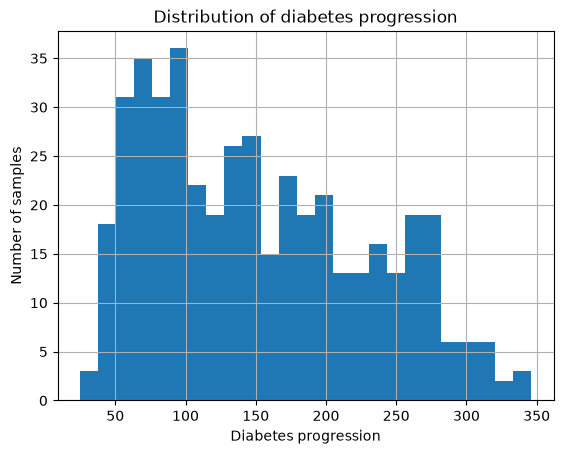

In [30]:
diabetes_df[TARGET].hist(bins=25)
plt.xlabel("Diabetes progression")
plt.ylabel("Number of samples")
plt.title("Distribution of diabetes progression")
plt.show()

Plot that shows how the age of the patient correlates with diabetes progression:

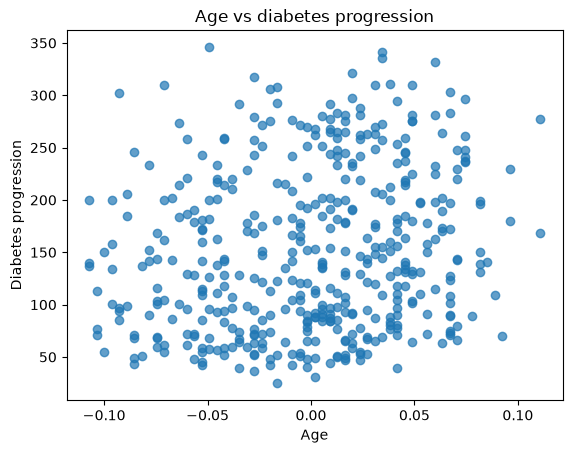

In [36]:
plt.scatter(diabetes_df["age"], diabetes_df[TARGET], alpha=0.7)
plt.xlabel("Age")
plt.ylabel("Diabetes progression")
plt.title("Age vs diabetes progression")
plt.show()

What is the relationship between body mass index and diabetes progression?

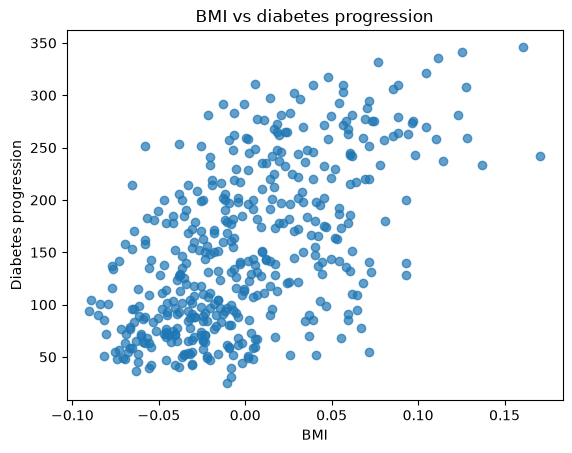

In [37]:
plt.scatter(diabetes_df["bmi"], diabetes_df[TARGET], alpha=0.7)
plt.xlabel("BMI")
plt.ylabel("Diabetes progression")
plt.title("BMI vs diabetes progression")
plt.show()

To what extent does blood pressure at baseline predict or correlate with long-term disease progression?

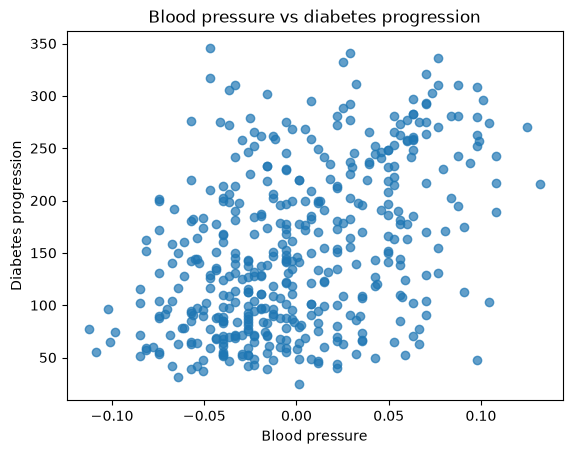

In [41]:
plt.scatter(diabetes_df["bp"], diabetes_df[TARGET], alpha=0.7)
plt.xlabel("Blood pressure")
plt.ylabel("Diabetes progression")
plt.title("Blood pressure vs diabetes progression")
plt.show()

How the level of each of the baseline serum biomarkers correlates with diabetes progression?

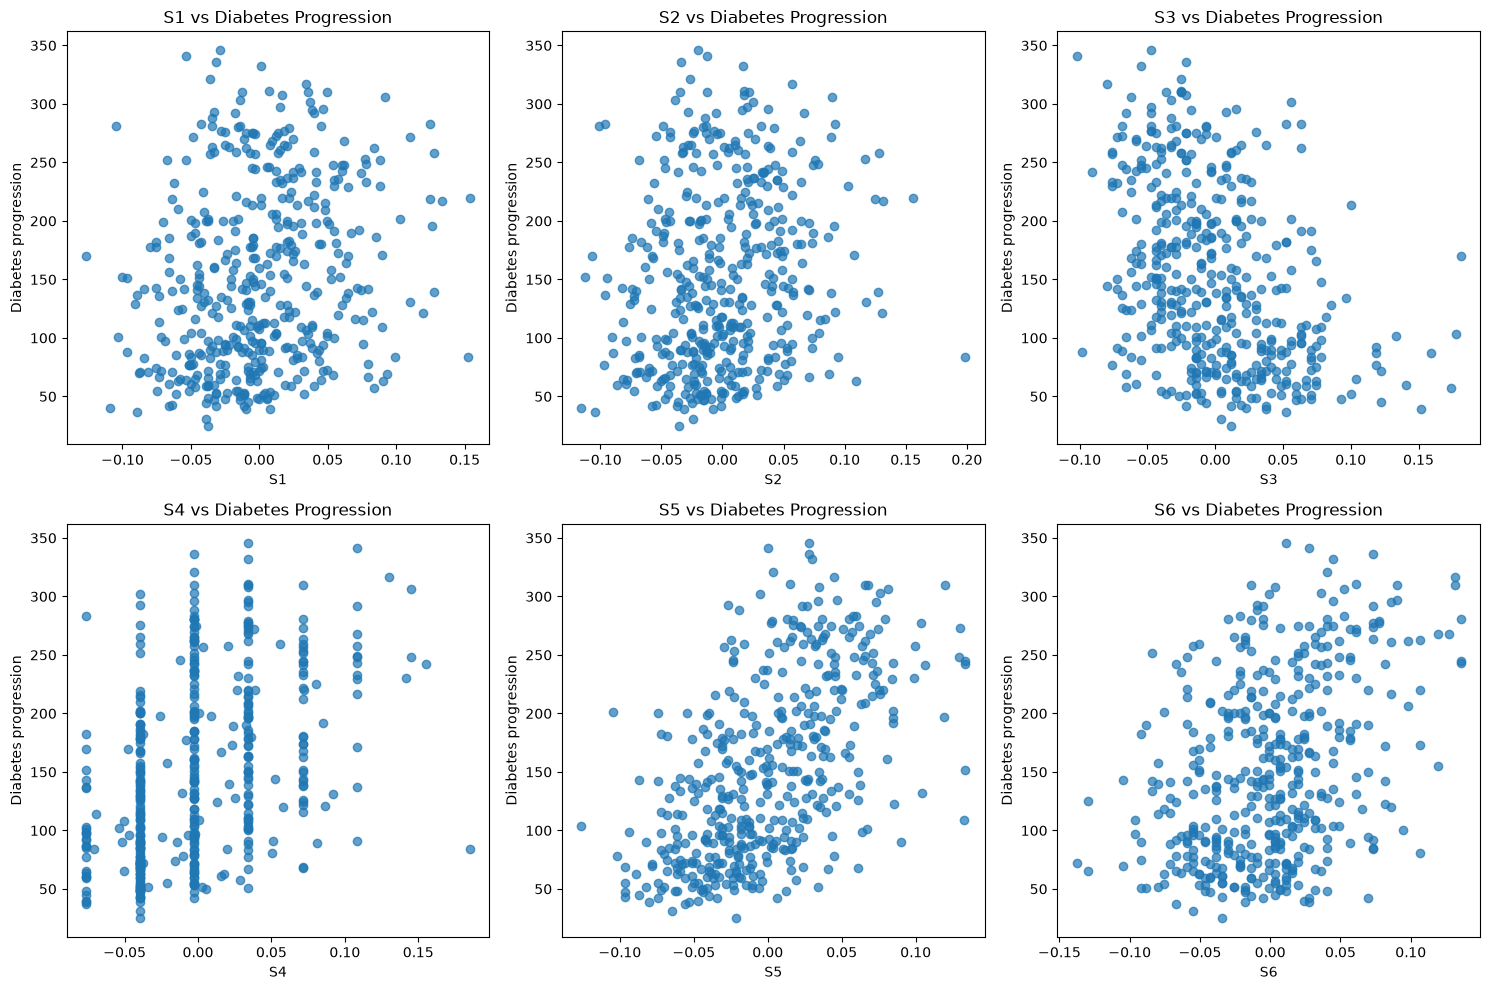

In [38]:
serum_cols = ["s1", "s2", "s3", "s4", "s5", "s6"]

fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(15, 10))
axes = axes.flatten()

for i, col in enumerate(serum_cols):
    ax = axes[i]
    ax.scatter(diabetes_df[col], diabetes_df[TARGET], alpha=0.7)
    ax.set_xlabel(col.upper())
    ax.set_ylabel("Diabetes progression")
    ax.set_title(f"{col.upper()} vs Diabetes Progression")

plt.tight_layout()
plt.show()

From all features we can see that the strongest correlations with diabetes progression are for BMI and S5 (which is possibly log of serum triglycerides level)

### 3.3 Correlation

- Calculate correlation using ar least 2 different methods.
- Identify the predictor most strongly correlated with the target.
- Compare results.
- Explain why correlation is not sufficient for feature selection or causal interpretation.

In [39]:
diabetes_df.corr(method="pearson")

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
age,1.000000,0.173737,0.185085,0.335428,0.260061,0.219243,-0.075181,0.203841,0.270774,0.301731,0.187889
sex,0.173737,1.000000,0.088161,0.241010,0.035277,0.142637,-0.379090,0.332115,0.149916,0.208133,0.043062
bmi,0.185085,0.088161,1.000000,0.395411,0.249777,0.261170,-0.366811,0.413807,0.446157,0.388680,0.586450
bp,0.335428,0.241010,0.395411,1.000000,0.242464,0.185548,-0.178762,0.257650,0.393480,0.390430,0.441482
s1,0.260061,0.035277,0.249777,0.242464,1.000000,0.896663,0.051519,0.542207,0.515503,0.325717,0.212022
s2,0.219243,0.142637,0.261170,0.185548,0.896663,1.000000,-0.196455,0.659817,0.318357,0.290600,0.174054
s3,-0.075181,-0.379090,-0.366811,-0.178762,0.051519,-0.196455,1.000000,-0.738493,-0.398577,-0.273697,-0.394789
s4,0.203841,0.332115,0.413807,0.257650,0.542207,0.659817,-0.738493,1.000000,0.617859,0.417212,0.430453
s5,0.270774,0.149916,0.446157,0.393480,0.515503,0.318357,-0.398577,0.617859,1.000000,0.464669,0.565883
s6,0.301731,0.208133,0.388680,0.390430,0.325717,0.290600,-0.273697,0.417212,0.464669,1.000000,0.382483


In [40]:
diabetes_df.corr(method="spearman")

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
age,1.000000,0.177463,0.200554,0.350859,0.262524,0.221711,-0.106973,0.221017,0.265176,0.296235,0.197822
sex,0.177463,1.000000,0.098079,0.261508,0.027790,0.134695,-0.394584,0.337524,0.174625,0.203277,0.037401
bmi,0.200554,0.098079,1.000000,0.397985,0.287829,0.295494,-0.371172,0.459068,0.491609,0.384664,0.561382
bp,0.350859,0.261508,0.397985,1.000000,0.275224,0.205638,-0.191033,0.280799,0.396071,0.381219,0.416241
s1,0.262524,0.027790,0.287829,0.275224,1.000000,0.878793,0.015308,0.520674,0.512864,0.332173,0.232429
s2,0.221711,0.134695,0.295494,0.205638,0.878793,1.000000,-0.197435,0.652283,0.349947,0.286483,0.195834
s3,-0.106973,-0.394584,-0.371172,-0.191033,0.015308,-0.197435,1.000000,-0.789694,-0.450420,-0.290863,-0.410022
s4,0.221017,0.337524,0.459068,0.280799,0.520674,0.652283,-0.789694,1.000000,0.640390,0.413700,0.448931
s5,0.265176,0.174625,0.491609,0.396071,0.512864,0.349947,-0.450420,0.640390,1.000000,0.453023,0.589416
s6,0.296235,0.203277,0.384664,0.381219,0.332173,0.286483,-0.290863,0.413700,0.453023,1.000000,0.350792


In [52]:
features = ["age", "sex", "bmi", "bp", "s1", "s2", "s3", "s4", "s5", "s6"]
dcor_results = []
for feature in features:
    pair = diabetes_df[[feature, TARGET]].dropna()
    dcor_results.append({
        "feature": feature,
        "Pearson": pair[feature].corr(pair[TARGET], method="pearson"),
        "Spearman": pair[feature].corr(pair[TARGET], method="spearman"),
        "Distance correlation": dcor.distance_correlation(
            pair[feature].to_numpy(), pair[TARGET].to_numpy()),})

pd.DataFrame(dcor_results).set_index("feature").round(3)

,Pearson,Spearman,Distance correlation
feature,,,
age,0.188,0.198,0.187
sex,0.043,0.037,0.048
bmi,0.586,0.561,0.548
bp,0.441,0.416,0.424
s1,0.212,0.232,0.227
s2,0.174,0.196,0.193
s3,-0.395,-0.410,0.390
s4,0.430,0.449,0.422
s5,0.566,0.589,0.565


As was detected visually, the correlation results confirm that bmi and s5 are the strongest univariate correlates with 1-year diabetes progression. Specifically by Spearman and Distance correlations the highest values are for s5, the bmi in the second place. By Pearson correlation it is vice versa.

But in general we can see good consistency in results between different correlation methods.

Correlation is not sufficient for feature selection because it ignores redundancy between predictors, misses nonlinear relationships and cannot separate confounding from a real effect. Correlation is not sufficient for causal interpretation because correlation != causation. So there could be confounding or directionality problem: feature could be correlated but not the cause of outcome as well as the outcome could be the reason of the feature.

### 4.4 Simple regression

Choose one predictor and fit a simple linear regression. Report and interpret:

- intercept;
- slope;
- the scale of the predictor;
- whether the slope is a causal effect.

In [43]:
X_simple = diabetes_df[["s5"]]
y_simple = diabetes_df[TARGET]

simple_model = LinearRegression()
simple_model.fit(X_simple, y_simple)

print("Intercept:", simple_model.intercept_)
print("Slope:", simple_model.coef_[0])

Intercept: 152.13348416289585
Slope: 916.1373745509138


When the s5 value is 0, the predicted target is 152. Because s5 has been mean-centered and scaled, a value of 0 corresponds exactly to the average log serum triglyceride level of the cohort.  
For each additional 1 unit of s5, the model predicts an average increase of approximately 916 units in target.
The predictor is pre-centered and scaled so the number here could not be interpreted directly. A literal "1-unit increase" represents an extreme, hypothetical shift far beyond any patient's actual measurement in the dataset.
The slope is not a causal effect, because it represents the associative relationship not the causal one, as described earlier.

### 4.5 Residual diagnostics

Produce:

- observed versus predicted plot;
- residuals versus fitted plot;
- residual histogram;
- Q-Q plot.

Discuss linearity, homoscedasticity, residual normality, unusual observations, and any limitations of the diagnostics.

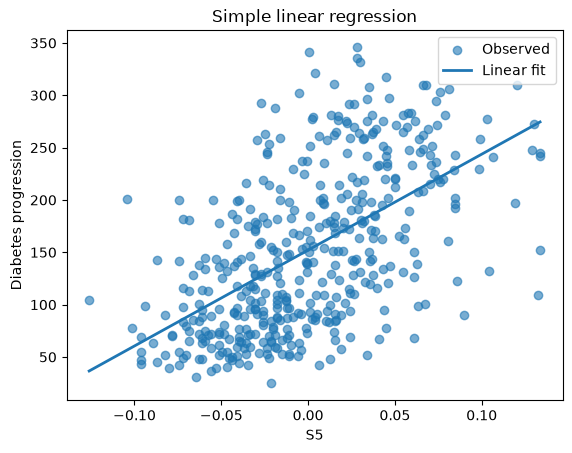

In [48]:
y_hat_simple = simple_model.predict(X_simple)
order = np.argsort(X_simple["s5"].to_numpy())

plt.scatter(X_simple["s5"], y_simple, alpha=0.6, label="Observed")

plt.plot(
    X_simple["s5"].to_numpy()[order],
    y_hat_simple[order],
    linewidth=2,
    label="Linear fit",
)

plt.xlabel("S5")
plt.ylabel("Diabetes progression")
plt.title("Simple linear regression")
plt.legend()
plt.show()

In [47]:
residuals = y_simple.to_numpy() - y_hat_simple

residual_df = pd.DataFrame({
    "observed": y_simple.to_numpy(),
    "predicted": y_hat_simple,
    "residual": residuals})

residual_df.head()

,observed,predicted,residual
0,151.0,170.371476,-19.371476
1,75.0,89.532400,-14.532400
2,141.0,154.754837,-13.754837
3,206.0,172.918575,33.081425
4,135.0,122.828412,12.171588


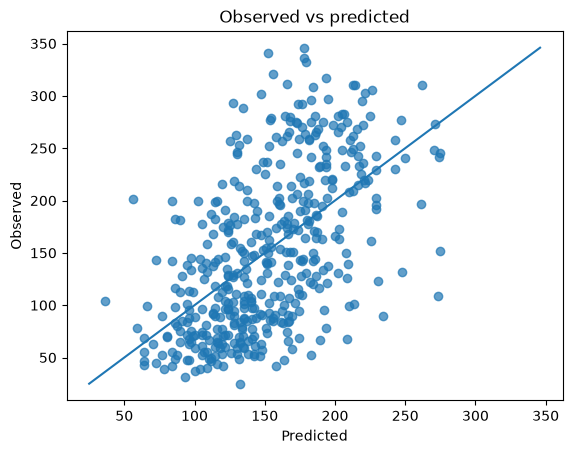

In [ ]:
plt.scatter(residual_df["predicted"], residual_df["observed"], alpha=0.7)
lims = [residual_df[["predicted","observed"]].min().min(), residual_df[["predicted","observed"]].max().max()]
plt.plot(lims, lims)
plt.xlabel("Predicted"); plt.ylabel("Observed"); plt.title("Observed vs predicted"); plt.show()

Linearity: There is no clear curve, so a straight line is a reasonable approximation of the relationship between s5 and disease progression.

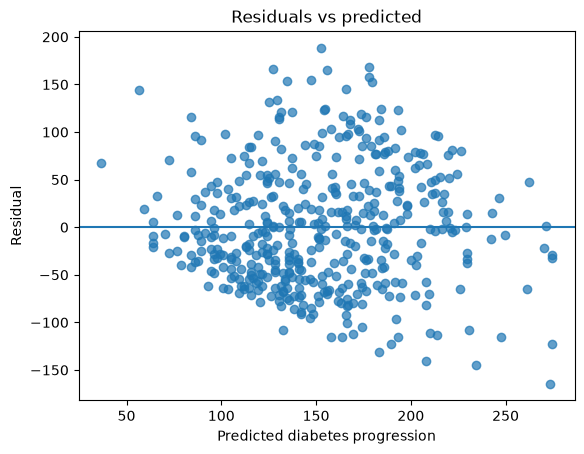

In [49]:
plt.scatter(
    residual_df["predicted"],
    residual_df["residual"],
    alpha=0.7)

plt.axhline(0)
plt.xlabel("Predicted diabetes progression")
plt.ylabel("Residual")
plt.title("Residuals vs predicted")
plt.show()

Homoscedasticity: there is a visible sign that there is a heteroscedasticity, the variance of the residuals widens with higher disease progression.

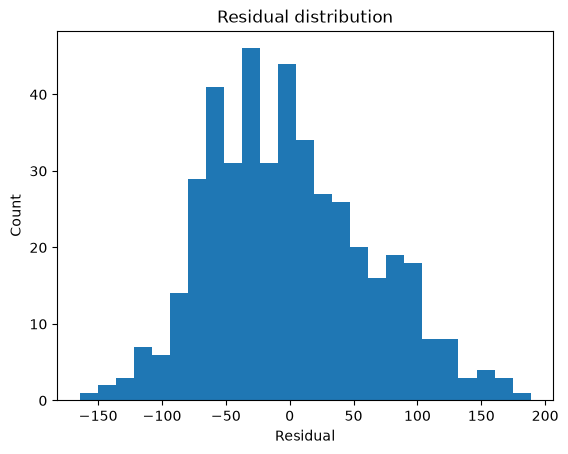

In [50]:
plt.hist(residuals, bins=25)
plt.xlabel("Residual")
plt.ylabel("Count")
plt.title("Residual distribution")
plt.show()

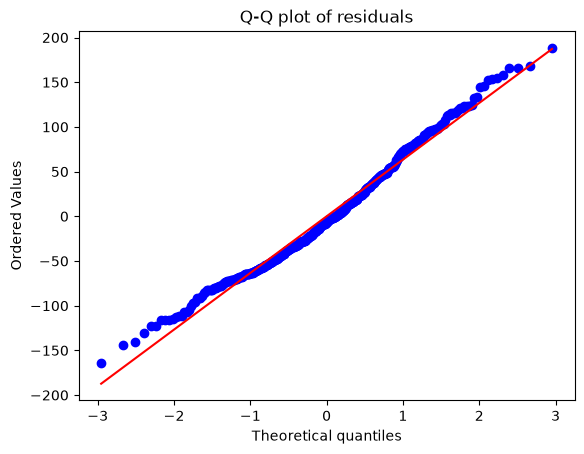

In [51]:
stats.probplot(residuals, dist="norm", plot=plt)
plt.title("Q-Q plot of residuals")
plt.show()

Residual normality: from the histogram and Q-Q plot above we can see that distribution of the residuals is near normal, but not ideally.

On residuals vs predicted plot there are a few outlier points that have high variance for low predicted values.

Finally, the linear model could describe partly the dependancy between s5 and target but far from full explanation. A single serum marker cannot fully explain a complex clinical outcome on its own, which justifies moving toward multivariate modeling with multiple features.

### 4.6 Multiple regression and multicollinearity

Fit a model using all available predictors. Inspect:

- coefficients;
- predictor correlations;
- possible multicollinearity;
- whether standardized predictors change coefficient interpretation.

In [55]:
X_multiple = diabetes_df[["age", "sex", "bmi", "bp", "s1", "s2", "s3", "s4", "s5", "s6"]]
y_multiple = diabetes_df[TARGET]

multiple_model = LinearRegression()
multiple_model.fit(X_multiple, y_multiple)

coef_table = pd.DataFrame({"feature": X_multiple.columns, "coefficient": multiple_model.coef_})

print(coef_table)

print("Intercept:", multiple_model.intercept_)

  feature  coefficient
0     age   -10.009866
1     sex  -239.815644
2     bmi   519.845920
3      bp   324.384646
4      s1  -792.175639
5      s2   476.739021
6      s3   101.043268
7      s4   177.063238
8      s5   751.273700
9      s6    67.626692
Intercept: 152.13348416289597


In [56]:
corr_matrix = X_multiple.corr()
print("Feature Correlation Matrix (Serum Biomarkers)")
print(corr_matrix.loc[["s1", "s2", "s3", "s4", "s5", "s6"], ["s1", "s2", "s3", "s4", "s5", "s6"]].round(3))

Feature Correlation Matrix (Serum Biomarkers)
       s1     s2     s3     s4     s5     s6
s1  1.000  0.897  0.052  0.542  0.516  0.326
s2  0.897  1.000 -0.196  0.660  0.318  0.291
s3  0.052 -0.196  1.000 -0.738 -0.399 -0.274
s4  0.542  0.660 -0.738  1.000  0.618  0.417
s5  0.516  0.318 -0.399  0.618  1.000  0.465
s6  0.326  0.291 -0.274  0.417  0.465  1.000


When we look at correlations among the serum markers we can see high correlations, especially for s1 and s2 (0.897). This means that features are sharing redundant information.
This multicollinearity causes standart errors of coefficients to inflate, making individual coefficient estimates unstable and sensitive to minor data changes.

With these standartized predictors the magnitude of the coefficients can be directly compared, but direct interpretation of 1-unit increase is irrelevant.

### 4.7 Train/test evaluation

Create a justified train/test split and report MAE, MSE, RMSE, and $R^2$. Compare simple and multiple regression on test data.

Explain whether the split answers the intended biological or clinical generalization question.

In [ ]:
evaluation_df = diabetes_df[["age", "sex", "bmi", "bp", "s1", "s2", "s3", "s4", "s5", "s6", TARGET]]

X = evaluation_df.drop(columns=TARGET)
y = evaluation_df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=RANDOM_STATE)

In [78]:
def regression_metrics(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "MSE": mean_squared_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred)}

results = []
# Model 1: s5 only
m1 = LinearRegression()
m1.fit(X_train[["s5"]], y_train)

for split_name, X_split, y_split in [
    ("train", X_train, y_train),
    ("test", X_test, y_test)]:
    pred = m1.predict(X_split[["s5"]])
    metrics = regression_metrics(y_split, pred)
    results.append({
        "model": "S5 only",
        "split": split_name,
        **metrics })


# Model 2: all features
m2_features = ['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']

m2 = LinearRegression()
m2.fit(X_train[m2_features], y_train)

for split_name, X_split, y_split in [
    ("train", X_train, y_train),
    ("test", X_test, y_test)]:
    pred = m2.predict(X_split[m2_features])
    metrics = regression_metrics(y_split, pred)
    results.append({
        "model": "All features",
        "split": split_name,
        **metrics })


In [79]:
results_df = pd.DataFrame(results)
results_df

,model,split,MAE,MSE,RMSE,R2
0,S5 only,train,52.265651,4076.887090,63.850506,0.314960
1,S5 only,test,49.275612,3861.319369,62.139515,0.338661
2,All features,train,42.131144,2777.124548,52.698430,0.533359
3,All features,test,48.216333,3312.355841,57.553070,0.432683


A standard randomized train/test split (80/20) is appropriate because the dataset observations are independent samples of individual patients.

The multivariable model with 10 features has lower error metrics and, at the same time, higher R2, than the univariate s5 model. This meanes that multivariable model better explain variance and reduce errors, confirming that combaining all available features in this case capture additive signals that a single biomarker misses.

A standart random split answers to the question of how well the model generalizes to unseen patients taken from the exact same underlying population distribution. But it cannot answer this question to a global population, because there are many external factors that have an effect on target.

### 4.8 Independent-task conclusion

Answer:

1. Which model generalized better?
The S5-only model shows no overfitting: test R² (0.339) is slightly higher than train (0.315) and test RMSE (62.1) is lower than train (63.9). This reversed gap could be random fluctuation from a small dataset. The all-features model shows a moderate gap: R² drops from 0.533 to 0.433 and RMSE rises from 52.7 to 57.6. That indicates mild overfitting from its 10 predictors, but it still performs better on test data than S5-only, so it generalizes better in absolute terms.
2. Did adding more variables help?
Yes. The multivariable model (with all features) achieved better overall predictive performance, having a higher test R2 and lower test error metrics. The improvement is real but modest, with R² still below 0.5 for test data, and it comes at the cost of interpretability and a larger train/test gap.
3. Are any regression assumptions questionable?
Multicollinearity: the serum biomarkers are higly correlated (s1 and s2 correlate at 0.90, s3 and s4 at -0.74, and s2 and s4 at 0.66.), this inflates the variance of the coefficients. Also the distribution of residuals is not completely normal and the residuals are heteroscedastic.
4. Are coefficient interpretations straightforward?
Not entirely. Because the predictors are standardized, coefficients are comparable in scale, but not in original units. The strong correlations between serum biomarkers make the individual coefficients unstable, so they shouldn’t be interpreted one by one.
5. What is one important limitation of the dataset or model?
The model captures predictive association, not biological causation. Many factors that are not measured could be confounders, as well as the dataset is pretty small (442 patients) so the generalisation to other population is uncertain.

Remember that the predictors from `load_diabetes()` are already standardized.